# Project 1, 665 extension: frozen features or fine-tuning?

For the same pretrained ViT, what do we gain or lose by updating its representation rather than training only a linear head?
Needs A6-H (P1_A) and your B1 and B3 photos (P1_B). No new photos, data, or deep-model training.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Mounted at /content/drive
project folder: /content/drive/MyDrive/p1
p1_utils: project folder /content/drive/MyDrive/p1 | OpenCV 4.14.0 | Colab: True
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'pottedplant', 'tvmonitor']     # TODO: your five classes (same in every notebook)

device: cuda


In [3]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [4]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [5]:
X224, _, _, _ = load_crops(224)     # needed here: the frozen encoder takes 224 px crops, like A6-H (X64 is not enough)
# Keep X224 as uint8 and convert one batch at a time: all of it as float32 is 10 GB, more than Colab's free RAM.

print("X224 shape:", X224.shape)
print("X224 dtype:", X224.dtype)

X224 shape: (16719, 224, 224, 3)
X224 dtype: uint8


In [6]:
# TODO Reload the ORIGINAL checkpoint (vit_tiny_patch16_224.augreg_in21k_ft_in1k, not your A6-H), freeze it, eval mode;
# extract the final normalized class-token feature for training (original and flipped views), validation, test, B1, and the
# B3 rotation series: load_b3_series(B3_DIR, 224, CHOSEN_FACTOR), keeping the records with r['factor'] == 'rotation'.
# Functions: timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k', pretrained=True, num_classes=0);
#    enc.eval(); p.requires_grad_(False); torch.no_grad(); x.flip(3)
import timm
CHOSEN_FACTOR = 'distance'
# Load original pretrained ViT
enc = timm.create_model(
    'vit_tiny_patch16_224.augreg_in21k_ft_in1k',
    pretrained=True,
    num_classes=0
).to(DEV)

# Freeze encoder
for p in enc.parameters():
    p.requires_grad_(False)

enc.eval()

# Original checkpoint normalization
mean = torch.tensor(enc.pretrained_cfg['mean'], device=DEV).view(1, 3, 1, 1)
std = torch.tensor(enc.pretrained_cfg['std'], device=DEV).view(1, 3, 1, 1)

# Extract features
def get_features(images, flip=False):
    features = []

    with torch.no_grad():
        for i in range(0, len(images), 32):
            x = torch.tensor(images[i:i+32], dtype=torch.float32, device=DEV)
            x = x.permute(0, 3, 1, 2) / 255.0

            if flip:
                x = x.flip(3)

            x = (x - mean) / std
            features.append(enc(x).cpu())

    return torch.cat(features)

# Training: original and flipped
feat_train = get_features(X224[idx_train])
feat_train_flip = get_features(X224[idx_train], flip=True)

# Validation and test
feat_val = get_features(X224[idx_val])
feat_test = get_features(X224[idx_test])

# B1 photos
B1_DIR = os.path.join(ROOT, 'photos', 'B1')
X1_224, y1, paths1 = load_photo_folder(B1_DIR, 224)
feat_b1 = get_features(X1_224)

# B3 rotation images only
B3_DIR = os.path.join(ROOT, 'photos', 'B3')
recs224 = load_b3_series(B3_DIR, 224, CHOSEN_FACTOR)
rotation_recs = [r for r in recs224 if r['factor'] == 'rotation']

X_rotation = np.stack([r['image'] for r in rotation_recs])
feat_b3_rotation = get_features(X_rotation)

print(feat_train.shape, feat_train_flip.shape)
print(feat_val.shape, feat_test.shape)
print(feat_b1.shape, feat_b3_rotation.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

torch.Size([7541, 192]) torch.Size([7541, 192])
torch.Size([797, 192]) torch.Size([8381, 192])
torch.Size([50, 192]) torch.Size([40, 192])


In [7]:
# TODO Reload check for A6-H, before comparing with it: recompute its VOC test mean per-class accuracy (19 classes)
# and confirm it matches Table 1 from P1_A. If it does not, this notebook's preprocessing differs from P1_A's
# (for example, A6 needs its checkpoint's mean and std, not the usual ImageNet values): fix that first.

import os
import numpy as np
import torch
import torch.nn.functional as F
import timm

checkpoint = os.path.join(ROOT, "checkpoints", "a6_h.pt")

model_a6h = timm.create_model(
    "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
    pretrained=False,
    num_classes=19
).to(DEV)

model_a6h.load_state_dict(
    torch.load(
        checkpoint,
        map_location=DEV,
        weights_only=True
    )
)

model_a6h.eval()

a6_mean = torch.tensor(
    model_a6h.pretrained_cfg["mean"],
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

a6_std = torch.tensor(
    model_a6h.pretrained_cfg["std"],
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

predictions = []
targets = []

with torch.no_grad():
    for start in range(0, len(idx_test), 32):
        ids = idx_test[start:start + 32]

        x = torch.as_tensor(
            np.asarray(X224[ids]),
            dtype=torch.float32,
            device=DEV
        )

        x = x.permute(0, 3, 1, 2) / 255.0
        x = (x - a6_mean) / a6_std

        logits = model_a6h(x)

        predictions.append(
            logits.argmax(dim=1).cpu().numpy()
        )

        targets.append(
            np.asarray(y)[ids]
        )

predictions = np.concatenate(predictions)
targets = np.concatenate(targets)

class_accuracies = []

for c in range(19):
    mask = targets == c

    if mask.sum() == 0:
        raise ValueError(f"No test examples for class {c}")

    class_accuracies.append(
        np.mean(predictions[mask] == targets[mask])
    )

a6h_test_accuracy = float(np.mean(class_accuracies))

table1_accuracy = 0.921

print("A6-H checkpoint:", checkpoint)
print("Normalization mean:", model_a6h.pretrained_cfg["mean"])
print("Normalization std:", model_a6h.pretrained_cfg["std"])
print("VOC test examples:", len(targets))
print("Classes:", len(class_accuracies))
print("A6-H VOC test mean per-class accuracy:", round(a6h_test_accuracy, 4))
print("P1_A reference accuracy:", table1_accuracy)
print("Absolute difference:", round(abs(a6h_test_accuracy - table1_accuracy), 6))

if abs(a6h_test_accuracy - table1_accuracy) <= 0.001:
    print("PASS: A6-H matches the previously reported result")
else:
    print("CHECK: A6-H differs from the reference result")
    print("Verify preprocessing and the original P1_A Table 1 value")


A6-H checkpoint: /content/drive/MyDrive/p1/checkpoints/a6_h.pt
Normalization mean: (0.5, 0.5, 0.5)
Normalization std: (0.5, 0.5, 0.5)
VOC test examples: 8381
Classes: 19
A6-H VOC test mean per-class accuracy: 0.921
P1_A reference accuracy: 0.921
Absolute difference: 2.3e-05
PASS: A6-H matches the previously reported result


In [8]:
# TODO Fit a new 19-way linear head, created right after torch.manual_seed(1) as for A6-H, with A6-H's loss, head learning rate, optimizer, batch size,
# epoch budget and validation-based selection; pick the flipped or original view of each training crop with probability 0.5
# per epoch.
# Functions: torch.manual_seed(1); nn.Linear(192, 19); torch.rand; torch.where
torch.manual_seed(1)
head = nn.Linear(192, 19).to(DEV)

opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)

for epoch in range(5):
    head.train()

    flip = torch.rand(len(feat_train), device=DEV) < 0.5
    X_train = torch.where(flip[:, None], feat_train_flip.to(DEV), feat_train.to(DEV))

    order = np.random.default_rng(epoch).permutation(len(X_train))

    for i in range(0, len(order), 32):
        b = order[i:i+32]

        loss = F.cross_entropy(
            head(X_train[b]),
            torch.tensor(y[idx_train[b]], dtype=torch.long, device=DEV)
        )

        opt.zero_grad()
        loss.backward()
        opt.step()

    head.eval()
    with torch.no_grad():
        pred = head(feat_val.to(DEV)).argmax(1)
        labels = torch.tensor(y[idx_val], dtype=torch.long, device=DEV)

        acc = torch.stack([
            (pred[labels == c] == c).float().mean()
            for c in range(19) if (labels == c).sum() > 0
        ]).mean().item()

    print(f"Epoch {epoch+1}: Validation = {acc:.4f}")

    if epoch == 0 or acc > best_val_acc:
        best_val_acc = acc
        best_state = {
            k: v.detach().clone()
            for k, v in head.state_dict().items()
        }

head.load_state_dict(best_state)

Epoch 1: Validation = 0.8631
Epoch 2: Validation = 0.8708
Epoch 3: Validation = 0.8724
Epoch 4: Validation = 0.8793
Epoch 5: Validation = 0.8759


<All keys matched successfully>

,model,VOC test mean per-class accuracy,B1 mean per-class accuracy
0,A6-frozen,0.888268,0.84
1,A6-H,0.920977,0.88


,model,total_parameters,trainable_parameters
0,A6-frozen,5528083,3667
1,A6-H,5528083,5528083


,stage,seconds,measurement
0,Frozen feature extraction,19.377245,Estimated from 512 training crops and flipped ...
1,Frozen head fitting,1.313709,Measured over 5 epochs
2,A6-H fine-tuning,NaN,Not recorded in this notebook


wrote 310 rows to /content/drive/MyDrive/p1/results/b3_results.csv


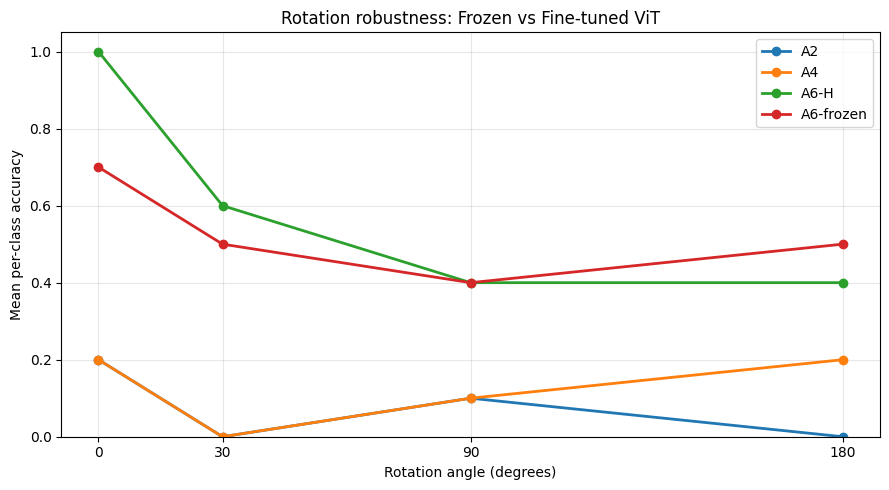

Comparison completed
B3 CSV updated: /content/drive/MyDrive/p1/results/b3_results.csv
Rotation plot: /content/drive/MyDrive/p1/results/frozen_vs_finetuned_rotation.png


In [9]:
# TODO Compare with A6-H: VOC test and B1 mean per-class accuracy, total and trainable parameters, training cost (feature
# extraction and head fitting separately), and a rotation plot. Add the frozen model's rotation rows to b3_results.csv with
# model 'A6-frozen' (b3_rows, then write_b3_csv: it keeps the A2, A4, and A6-H rows already in the file).
# Functions: sum(p.numel() for p in m.parameters() if p.requires_grad); time.time(); plt.plot;
#    b3_rows(recs, 'A6-frozen', probs); write_b3_csv(rows, path)

import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

RESULTS_DIR = os.path.join(ROOT, "results")
CKPT_DIR = os.path.join(ROOT, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)

model_a6h = timm.create_model(
    "vit_tiny_patch16_224.augreg_in21k_ft_in1k",
    pretrained=False,
    num_classes=19
).to(DEV)

model_a6h.load_state_dict(
    torch.load(
        os.path.join(CKPT_DIR, "a6_h.pt"),
        map_location=DEV,
        weights_only=True
    )
)

model_a6h.eval()
enc.eval()
head.eval()

a6_mean = torch.tensor(
    model_a6h.pretrained_cfg["mean"],
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

a6_std = torch.tensor(
    model_a6h.pretrained_cfg["std"],
    dtype=torch.float32,
    device=DEV
).view(1, 3, 1, 1)

def a6_predict(images, batch_size=32):
    results = []

    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            batch = np.asarray(images[start:start + batch_size])

            x = torch.as_tensor(
                batch,
                dtype=torch.float32,
                device=DEV
            ).permute(0, 3, 1, 2) / 255.0

            x = (x - a6_mean) / a6_std

            probs = F.softmax(
                model_a6h(x),
                dim=1
            )

            results.append(probs.cpu().numpy())

    return np.concatenate(results)

def frozen_predict(features, batch_size=1024):
    results = []

    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            x = features[start:start + batch_size].to(DEV)
            probs = F.softmax(head(x), dim=1)
            results.append(probs.cpu().numpy())

    return np.concatenate(results)

def mean_class_accuracy(labels, predictions):
    labels = np.asarray(labels)
    predictions = np.asarray(predictions)

    return float(np.mean([
        np.mean(predictions[labels == c] == c)
        for c in np.unique(labels)
    ]))

voc_labels = np.asarray(y)[idx_test]
b1_labels = np.asarray(y1)

probs_frozen_test = frozen_predict(feat_test)
probs_frozen_b1 = frozen_predict(feat_b1)
probs_frozen_rotation = frozen_predict(feat_b3_rotation)

probs_a6_test = []

with torch.no_grad():
    for start in range(0, len(idx_test), 32):
        ids = idx_test[start:start + 32]
        probs_a6_test.append(a6_predict(X224[ids]))

probs_a6_test = np.concatenate(probs_a6_test)

probs_a6_b1 = a6_predict(X1_224)
probs_a6_rotation = a6_predict(X_rotation)

accuracy_rows = []

for name, probs_test, probs_b1 in [
    ("A6-frozen", probs_frozen_test, probs_frozen_b1),
    ("A6-H", probs_a6_test, probs_a6_b1)
]:
    accuracy_rows.append({
        "model": name,
        "VOC test mean per-class accuracy": mean_class_accuracy(
            voc_labels,
            probs_test.argmax(axis=1)
        ),
        "B1 mean per-class accuracy": mean_class_accuracy(
            b1_labels,
            probs_b1.argmax(axis=1)
        )
    })

accuracy_df = pd.DataFrame(accuracy_rows)
display(accuracy_df)

def count_total(model):
    return sum(p.numel() for p in model.parameters())

def count_trainable(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

parameter_df = pd.DataFrame([
    {
        "model": "A6-frozen",
        "total_parameters": count_total(enc) + count_total(head),
        "trainable_parameters": count_trainable(enc) + count_trainable(head)
    },
    {
        "model": "A6-H",
        "total_parameters": count_total(model_a6h),
        "trainable_parameters": count_trainable(model_a6h)
    }
])

display(parameter_df)

def synchronize():
    if str(DEV).startswith("cuda"):
        torch.cuda.synchronize()

sample_size = min(512, len(idx_train))
sample_ids = np.asarray(idx_train[:sample_size])

synchronize()
start_time = time.time()

_ = get_features(X224[sample_ids])
_ = get_features(X224[sample_ids], flip=True)

synchronize()
feature_sample_seconds = time.time() - start_time

feature_extraction_seconds = (
    feature_sample_seconds
    * len(idx_train)
    / sample_size
)

torch.manual_seed(1)

head_benchmark = nn.Linear(
    feat_train.shape[1],
    19
).to(DEV)

optimizer_benchmark = torch.optim.AdamW(
    head_benchmark.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

train_features = feat_train.to(DEV)
train_features_flip = feat_train_flip.to(DEV)

train_labels = torch.as_tensor(
    np.asarray(y)[idx_train],
    dtype=torch.long,
    device=DEV
)

synchronize()
start_time = time.time()

for epoch in range(5):
    head_benchmark.train()

    flip = torch.rand(
        len(train_features),
        device=DEV
    ) < 0.5

    selected_features = torch.where(
        flip[:, None],
        train_features_flip,
        train_features
    )

    order = np.random.default_rng(epoch).permutation(
        len(selected_features)
    )

    for start in range(0, len(order), 32):
        ids = order[start:start + 32]

        logits = head_benchmark(selected_features[ids])
        loss = F.cross_entropy(
            logits,
            train_labels[ids]
        )

        optimizer_benchmark.zero_grad()
        loss.backward()
        optimizer_benchmark.step()

synchronize()
head_fitting_seconds = time.time() - start_time

cost_df = pd.DataFrame([
    {
        "stage": "Frozen feature extraction",
        "seconds": feature_extraction_seconds,
        "measurement": "Estimated from 512 training crops and flipped views"
    },
    {
        "stage": "Frozen head fitting",
        "seconds": head_fitting_seconds,
        "measurement": "Measured over 5 epochs"
    },
    {
        "stage": "A6-H fine-tuning",
        "seconds": np.nan,
        "measurement": "Not recorded in this notebook"
    }
])

display(cost_df)

b3_path = os.path.join(
    RESULTS_DIR,
    "b3_results.csv"
)

if not os.path.isfile(b3_path):
    raise FileNotFoundError(
        "Run the B3 evaluation in P1_B first"
    )

existing_df = pd.read_csv(b3_path)

new_rows = b3_rows(
    rotation_recs,
    "A6-frozen",
    probs_frozen_rotation
)

new_df = pd.DataFrame(new_rows)

existing_df = existing_df[
    ~(
        (existing_df["model"] == "A6-frozen")
        & (existing_df["factor"] == "rotation")
    )
].copy()

combined_df = pd.concat(
    [existing_df, new_df],
    ignore_index=True
)

write_b3_csv(
    combined_df.to_dict("records"),
    b3_path
)

rotation_df = combined_df[
    combined_df["factor"] == "rotation"
].copy()

rotation_df["correct"] = pd.to_numeric(
    rotation_df["correct"]
)

rotation_df["angle"] = (
    rotation_df["condition"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(float)
)

plt.figure(figsize=(9, 5))

for model_name in ["A2", "A4", "A6-H", "A6-frozen"]:
    subset = rotation_df[
        rotation_df["model"] == model_name
    ]

    if len(subset) == 0:
        continue

    grouped = (
        subset.groupby("angle")["correct"]
        .mean()
        .sort_index()
    )

    plt.plot(
        grouped.index,
        grouped.values,
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xlabel("Rotation angle (degrees)")
plt.ylabel("Mean per-class accuracy")
plt.title("Rotation robustness: Frozen vs Fine-tuned ViT")
plt.ylim(0, 1.05)
plt.xticks(sorted(rotation_df["angle"].dropna().unique()))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

rotation_plot_path = os.path.join(
    RESULTS_DIR,
    "frozen_vs_finetuned_rotation.png"
)

plt.savefig(
    rotation_plot_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

accuracy_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "frozen_vs_finetuned_accuracy.csv"
    ),
    index=False
)

parameter_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "frozen_vs_finetuned_parameters.csv"
    ),
    index=False
)

cost_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "frozen_vs_finetuned_cost.csv"
    ),
    index=False
)

print("Comparison completed")
print("B3 CSV updated:", b3_path)
print("Rotation plot:", rotation_plot_path)
